In [52]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [53]:
datas =pd.DataFrame( ({"message": ["I can't login",
                                  "My password doesn't work",
                                  "Payment failed",
                                  "I was charged twice",
                                  "The application keeps scrashing",
                                  "The website shows an error",
                                  "Where is my order?",
                                  "My package hasn't arrived",
                                  "What are your opening hours?",
                                  "How can I contact support?"],
                      "category": ["account", 
                                   "account",
                                   "payment",
                                   "payment",
                                   "technical",
                                   "technical",
                                   "order",
                                   "order",
                                   "general",
                                   "general"]}))
                     
                            
                                  

In [54]:
data= pd.read_csv('support_tickets_100.csv')
data
                

,message,category
0,What services do you provide,general
1,The page keeps loading without opening,technical
2,My package is delayed,order
3,The application stopped working,technical
4,I found a technical error,technical
...,...,...
95,Where is my order,order
96,The tracking information is not updating,order
97,I cannot authenticate my account,account
98,How can I get help from your team,general


In [55]:
data.isnull().sum()

message     0
category    0
dtype: int64

In [56]:
data

,message,category
0,What services do you provide,general
1,The page keeps loading without opening,technical
2,My package is delayed,order
3,The application stopped working,technical
4,I found a technical error,technical
...,...,...
95,Where is my order,order
96,The tracking information is not updating,order
97,I cannot authenticate my account,account
98,How can I get help from your team,general


(array([20.,  0., 20.,  0.,  0., 20.,  0., 20.,  0., 20.]),
 array([0. , 0.4, 0.8, 1.2, 1.6, 2. , 2.4, 2.8, 3.2, 3.6, 4. ]),
 <BarContainer object of 10 artists>)

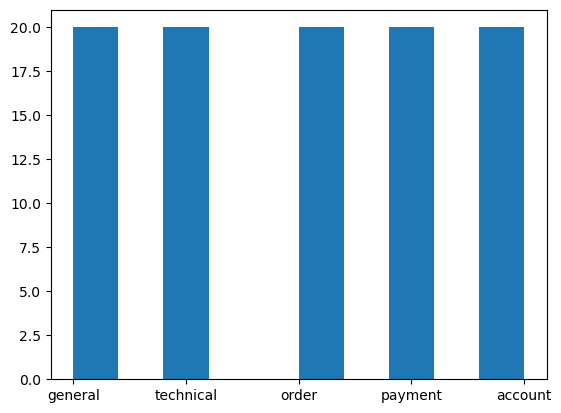

In [57]:
plt.hist(data["category"])

In [58]:
le = LabelEncoder()

In [59]:
data["category"] = le.fit_transform(data["category"])

In [62]:
print(le.classes_)

['account' 'general' 'order' 'payment' 'technical']


In [64]:
joblib.dump(le, 'label_encoder.pkl')
print('save')

save


In [40]:
data.shape

(100, 2)

In [41]:
data

,message,category
0,What services do you provide,1
1,The page keeps loading without opening,4
2,My package is delayed,2
3,The application stopped working,4
4,I found a technical error,4
...,...,...
95,Where is my order,2
96,The tracking information is not updating,2
97,I cannot authenticate my account,0
98,How can I get help from your team,1


In [42]:
x = data["message"]
y = data["category"].astype('int16')

In [43]:
x

0                 What services do you provide
1       The page keeps loading without opening
2                        My package is delayed
3              The application stopped working
4                    I found a technical error
                        ...                   
95                           Where is my order
96    The tracking information is not updating
97            I cannot authenticate my account
98           How can I get help from your team
99                   The application is frozen
Name: message, Length: 100, dtype: object

In [44]:
y

0     1
1     4
2     2
3     4
4     4
     ..
95    2
96    2
97    0
98    1
99    4
Name: category, Length: 100, dtype: int16

In [45]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [46]:
x_train.shape, x_test.shape

((80,), (20,))

In [47]:
model_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 5000,
        ngram_range = (1, 2)
    )),
    ('classifier', LogisticRegression(
        max_iter = 100,
        C= 1.0,
        solver= 'lbfgs',
    
    ))
])

model_pipeline

In [48]:
model_pipeline.fit(x_train, y_train)

,steps,"[('tfidf', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


In [49]:
y_pred = model_pipeline.predict(x_test)

In [50]:
y_test

83    3
53    3
70    2
45    0
44    3
39    0
22    3
80    2
10    0
0     1
18    0
30    0
73    4
33    3
90    1
4     4
76    2
77    3
12    2
31    4
Name: category, dtype: int16

In [51]:
message = input("Enter a support message: ")

prediction = model_pipeline.predict([message])

print('Predicted Category:', prediction[0])

Enter a support message:   I can't get into my account


Predicted Category: 0


In [24]:
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print("=="*16)
print(classification_report(y_test, y_pred))

Accuracy Score: 0.9000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.80      0.89         5
           1       0.67      1.00      0.80         2
           2       1.00      0.75      0.86         4
           3       1.00      1.00      1.00         6
           4       0.75      1.00      0.86         3

    accuracy                           0.90        20
   macro avg       0.88      0.91      0.88        20
weighted avg       0.93      0.90      0.90        20



In [25]:
import seaborn as sns

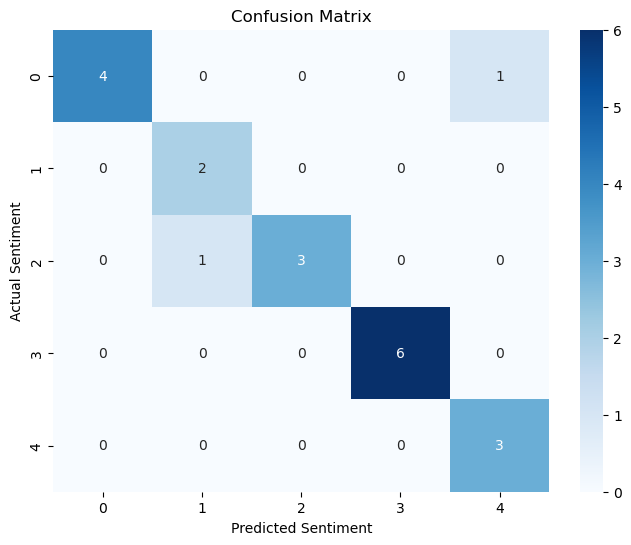

In [26]:
plt.figure(figsize=(8, 6))

cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=model_pipeline.classes_, 
            yticklabels=model_pipeline.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()


In [27]:
joblib.dump(model_pipeline, 'support_ticket_classifier.plk')
print('save')

save
